In [1]:
import os

os.environ['MKL_THREADING_LAYER'] = 'SEQUENTIAL'

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torchvision import datasets,transforms
import matplotlib.pyplot as plt

batch_size = 512
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
trainloader = torch.utils.data.DataLoader(datasets.MNIST('data',train=True,download = True,
              transform=transforms.Compose([transforms.ToTensor()])),batch_size=batch_size,shuffle=True)
testloader = torch.utils.data.DataLoader(datasets.MNIST('data',train=False,download=True,
              transform=transforms.Compose([transforms.ToTensor()])),batch_size=batch_size,shuffle=True)
print("训练数据形状:", trainloader.dataset.data.shape)
print("测试数据形式:", testloader.dataset.data.shape)

100.0%
100.0%
100.0%
100.0%

训练数据形状: torch.Size([60000, 28, 28])
测试数据形式: torch.Size([10000, 28, 28])


In [2]:
#补全以下代码
class Net(nn.Module):
  def __init__(self):
    super(Net,self).__init__()
    self.conv1 = nn.Conv2d(1,6,kernel_size=5,padding=2)  #输入通道1, 输出通道6, 卷积核5x5,padding=2
    self.conv2 = nn.Conv2d(6,16,kernel_size=5)  #输入通道6, 输出通道16, 卷积核5x5
    self.fc1 = nn.Linear(5*5*16,120)  #全连接层，输入5*5*16, 输出120
    self.fc2 = nn.Linear(120,84)  #全连接层，输入120, 输出84
    self.clf = nn.Linear(84,10)  #分类层，输入84, 输出10

  def forward(self,x):
    #conv1
    x = self.conv1(x)
    #激活函数sigmoid()
    x = torch.sigmoid(x)
    #平均池化层，kernel=2x2, 步长2
    x = F.avg_pool2d(x,kernel_size=2,stride=2)

    #conv2
    x = self.conv2(x)
    #激活函数sigmoid()
    x = torch.sigmoid(x)
    #平均池化层，2x2, 步长2
    x = F.avg_pool2d(x,kernel_size=2,stride=2)

    #展平，从第1维开始展平
    x = torch.flatten(x,1)

    #全连接层1
    x = self.fc1(x)
    #激活函数sigmoid()
    x = torch.sigmoid(x)

    #全连接层2
    x = self.fc2(x)
    #激活函数sigmoid()
    x = torch.sigmoid(x)

    #分类层
    x = self.clf(x)
    return x


model = Net().to(device)
optimizer = optim.Adam(model.parameters(), lr = 1e-2)
model

Net(
  (conv1): Conv2d(1, 6, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2))
  (conv2): Conv2d(6, 16, kernel_size=(5, 5), stride=(1, 1))
  (fc1): Linear(in_features=400, out_features=120, bias=True)
  (fc2): Linear(in_features=120, out_features=84, bias=True)
  (clf): Linear(in_features=84, out_features=10, bias=True)
)

In [3]:
epochs = 30
accs,losses = [], []
for epoch in range(epochs):
  for batch_idx,(x,y) in enumerate(trainloader):
    x,y = x.to(device),y.to(device)
    optimizer.zero_grad()
    out = model(x)
    loss = F.cross_entropy(out,y)
    loss.backward()
    optimizer.step()

  correct = 0
  testloss = 0
  with torch.no_grad():
    for batch_idx,(x,y) in enumerate(testloader):
      x,y = x.to(device),y.to(device)
      out = model(x)
      testloss += F.cross_entropy(out,y).item()
      pred = out.max(dim=1,keepdim=True)[1]
      correct += pred.eq(y.view_as(pred)).sum().item()

  acc = correct/len(testloader.dataset)
  testloss = testloss/(batch_idx+1)
  accs.append(acc)
  losses.append(testloss)
  print('epoch:{}, loss:{:.4f}, acc:{:.4f}'.format(epoch,testloss,acc))

epoch:0, loss:2.3018, acc:0.1135
epoch:1, loss:2.3014, acc:0.1135
epoch:2, loss:1.9102, acc:0.2204
epoch:3, loss:0.7870, acc:0.6935
epoch:4, loss:0.4014, acc:0.8494
epoch:5, loss:0.2564, acc:0.9184
epoch:6, loss:0.1762, acc:0.9481
epoch:7, loss:0.1289, acc:0.9598
epoch:8, loss:0.1157, acc:0.9665
epoch:9, loss:0.1171, acc:0.9651
epoch:10, loss:0.0859, acc:0.9721
epoch:11, loss:0.1241, acc:0.9619
epoch:12, loss:0.0848, acc:0.9740
epoch:13, loss:0.0916, acc:0.9717
epoch:14, loss:0.0803, acc:0.9755
epoch:15, loss:0.0774, acc:0.9768
epoch:16, loss:0.1006, acc:0.9706
epoch:17, loss:0.0640, acc:0.9801
epoch:18, loss:0.0773, acc:0.9752
epoch:19, loss:0.0626, acc:0.9802
epoch:20, loss:0.1096, acc:0.9679
epoch:21, loss:0.0625, acc:0.9806
epoch:22, loss:0.0849, acc:0.9731
epoch:23, loss:0.0828, acc:0.9760
epoch:24, loss:0.0796, acc:0.9751
epoch:25, loss:0.0673, acc:0.9798
epoch:26, loss:0.0572, acc:0.9829
epoch:27, loss:0.0641, acc:0.9811
epoch:28, loss:0.0672, acc:0.9792
epoch:29, loss:0.0605, a

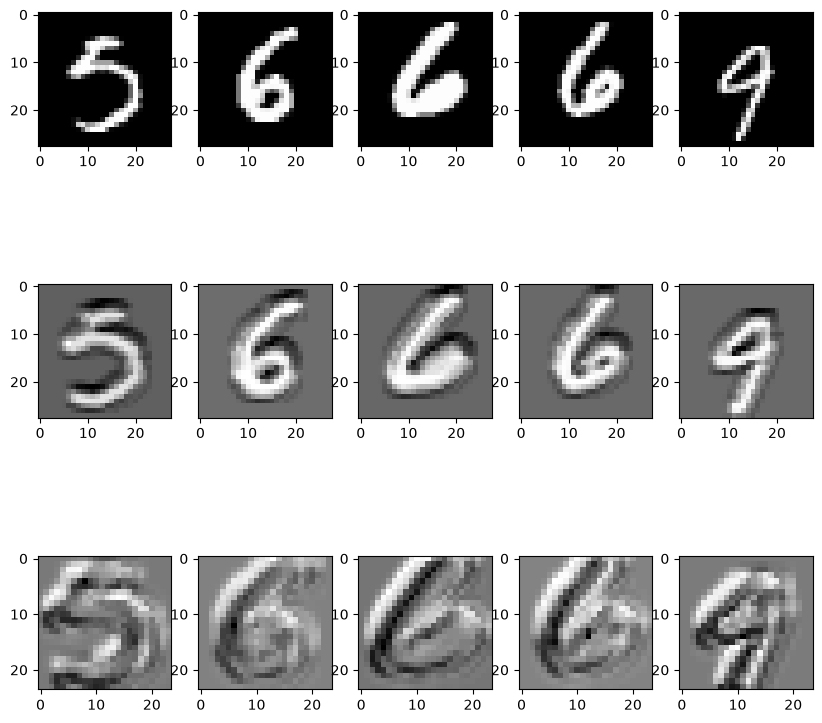

In [4]:
feature1 = F.sigmoid(model.conv1(x))
# feature1 = F.avg_pool2d(feature1,kernel_size=2,stride=2)
feature2 = F.sigmoid(model.conv2(feature1))
# feature2 = F.avg_pool2d(feature2,kernel_size=2,stride=2)

n = 5
img = x.detach().cpu().numpy()[:n]
feature_map1 = feature1.detach().cpu().numpy()[:n]
feature_map2 = feature2.detach().cpu().numpy()[:n]

fig, ax = plt.subplots(3, n, figsize=(10,10))
for i in range(n):
  ax[0,i].imshow(img[i].sum(0),cmap='gray')
  # ax[0,i].axis('off')
  ax[1,i].imshow(feature_map1[i].sum(0),cmap='gray')
  # ax[1,i].axis('off')
  ax[2,i].imshow(feature_map2[i].sum(0),cmap='gray')
  # ax[1,i].axis('off')
plt.show()